In [37]:
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent))

from utils.joint_plots import discrete_plot_joint, continuous_plot_joint
from utils.conditional_prob import conditional_plot
from utils.triple_plot import normality_report


In [38]:
df = pd.read_csv("../data/datos_inmobiliarios_clean.csv")

In [39]:
df

,property_type,price_amount,admin_fee,price_per_m2,area_built_m2,area_private_m2,bedrooms,bathrooms,parking_spaces,stratum,...,locality,neighborhood,latitude,longitude,amenities,agency_name,publisher_type,pub_month,mod_month,log_price_amount
0,casa,8.800000e+08,736000.00,5.500000e+06,160.0000,151.00,3.0,3.0,2,4.0,...,Suba,UB. Hacienda Cordoba Niza,4.711642,-74.062946,Alarma|Baño Auxiliar|Calentador|Canchas Deport...,Particular / Venta Directa,Particular,2023-01,2026-06,20.595432
1,casa,6.500000e+08,271123.04,4.237288e+06,153.4000,153.40,4.0,2.0,1,3.0,...,Barrios Unidos,Benjamin Herrera,4.655459,-74.073723,Baño Auxiliar|Colegios / Universidades|Estudio...,Particular / Venta Directa,Particular,2023-01,2026-07,20.292483
2,casa,6.250000e+08,643500.00,5.208333e+06,120.0000,120.00,4.0,3.0,2,5.0,...,Usaquen,Lagos DE Torca,4.764007,-74.042742,Baño Auxiliar|Calentador|Cancha de Tennis|Canc...,Particular / Venta Directa,Particular,2023-02,2026-06,20.253262
3,apartamento,4.700000e+08,560000.00,8.392857e+06,56.0000,58.00,1.0,2.0,1,4.0,...,Usaquen,Cedritos,4.721554,-74.036146,Ascensor|Barra estilo americano|Baño Auxiliar|...,Particular / Venta Directa,Particular,2023-03,2026-07,19.968243
4,apartamento,1.170000e+09,869954.98,1.456883e+07,79.4730,72.91,2.0,2.0,2,6.0,...,Usaquen,Santa Paula,4.685839,-74.047089,Ascensor|Baño Auxiliar|Calentador|Circuito cer...,B&R INMOBILIARIA,inmobiliaria,2023-03,2026-06,20.880270
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20437,casa,5.799000e+08,130221.92,2.978578e+06,199.0000,192.00,6.0,3.0,1,3.0,...,Fontibón,Centro Fontibon,4.676469,-74.136465,Alcantarillado|Baño Auxiliar|Cerca centro come...,Organización Inmobiliaria Diaz Castro S.A.S,inmobiliaria,2023-10,2026-06,20.178366
20438,casa,6.000000e+08,142990.98,4.641304e+06,134.3400,126.00,5.0,3.0,1,3.0,...,Engativá,Lujan,4.682503,-74.099924,Cerca a sector comercial|Cerca centro comercia...,GRUPO EMPRESARIAL OIKOS S.A.S,inmobiliaria,2023-10,2026-07,20.212440
20439,apartamento,6.500000e+08,410792.00,7.271865e+06,89.3400,90.00,3.0,3.0,1,4.0,...,Teusaquillo,EL Recuerdo,4.628558,-74.083638,Ascensor|Baño Auxiliar|Calentador|Cerca a sect...,ESTRATEGIAS COMERCIALES Y DE MERCADEO S.A.,inmobiliaria,2023-11,2026-06,20.292483
20440,apartamento,1.870000e+08,146713.70,4.512879e+06,41.9696,41.00,2.0,1.0,1,2.0,...,Suba,Pinar DE Suba,4.755939,-74.078061,Ninguna,VELEZ OSORIO & COMPAÑIA,inmobiliaria,2023-11,2026-06,19.046619


# Distribuciones conjuntas e inferencia multivariada


## Densidades conjunta discretas

In [40]:
partners = [
    ('stratum', 'city'),
    ('stratum', 'property_type'),
    ('stratum', 'publisher_type'),
    ('property_type', 'city'),
    ('publisher_type', 'property_type'),
    ]

In [41]:
for partner in partners:
    print(f"Plotting {partner[0]} vs {partner[1]}")
    discrete_plot_joint(df, partner[0], partner[1])

Plotting stratum vs city


Plotting stratum vs property_type


Plotting stratum vs publisher_type


Plotting property_type vs city


Plotting publisher_type vs property_type


## Densidades conjuntas continuas

In [42]:
partners = [
    ('area_private_m2', 'log_price_amount'),
    ('area_built_m2', 'area_private_m2'),
    ('admin_fee', 'log_price_amount'),
    ('area_built_m2', 'log_price_amount')
]

In [43]:
for partner in partners:
    print(f"Plotting {partner[0]} vs {partner[1]}")
    continuous_plot_joint(df, partner[0], partner[1])

Plotting area_private_m2 vs log_price_amount


Plotting area_built_m2 vs area_private_m2


Plotting admin_fee vs log_price_amount


Plotting area_built_m2 vs log_price_amount


# Condicionales

In [44]:
conditional_plot(df, given_col="area_built_m2", free_col="log_price_amount")


Note que conforme aumenta el area construida la probabilidad condicional muestra algo muy claro y es que los precios altos se hacen mas probbales y los bajos mas improbables, el efecto contrario ocurre al disminuir el area construida, esto respalda lo que se esperaria en el contexto pues es logico que a mayor metraje mayor precio, esto mismo se logra apreciar en las matrices de correlacion de bivariate_eda, solo que ahora se suma la posibilidad de ver co,o va cambiando la probabilidad.

In [45]:
conditional_plot(df, given_col="admin_fee", free_col="log_price_amount")


Aca vuelve a observarse un claro comportamiento cambianrte de los precios segun la variable condicionada admin fee, pues el comportamiento de esta es analoga a la distribucion dada el area construida, pues muestra como a mayor cuota de administracion es mas probable que las biviendas sean mas caras y veceversa, aunque para este caso y el anterior es fundamental destacar que si bien la probabilidad condicional de que la bivienda sea cara aumenta, sin dicha condicion bivciendas de tales precios son realmente poco comunes, es decir fijar el espacio muestral a biviendas de esas caracteristicas si que altera de manera drastica el comportamiento del general de la muestra.

## Adicionando al analisis norte contra sur del cuaderno

In [46]:
# 1. Fusionar variantes sin tilde con su versión con tilde
df['locality'] = df['locality'].replace({
    'Engativa': 'Engativá',
    'Fontibon': 'Fontibón',
})

# 2. Listas finales (ya sin duplicados)
norte = [
    'Usaquen',
    'Chapinero',
    'Suba',
    'Barrios Unidos',
    'Teusaquillo',
    'Engativá',
    'Fontibón',
]

sur = [
    'Kennedy',
    'Rafael Uribe',
    'Tunjuelito',
    'Puente Aranda',
    'Ciudad Bolivar',
    'Santafe',
    'San Cristobal',
    'Antonio Nariño',
    'Bosa',
    'LA Candelaria',
    'Los Martires',
    'Usme',
]

# Columna booleana: True si la localidad es del norte, False si es del sur
df['norte'] = df['locality'].isin(norte)

df_bogota = df[df['city'] == 'Bogotá']

df_norte = df_bogota[df_bogota['norte']].copy()
df_sur = df_bogota[~df_bogota['norte']].copy()


In [47]:
conditional_plot(
    df_norte,
    given_col="admin_fee",
    free_col="log_price_amount",
    title='Densidad condicional de Log Price Amount dado Admin Fee al norte'
    )


In [48]:
conditional_plot(
    df_sur,
    given_col="admin_fee",
    free_col="log_price_amount",
    title='Densidad condicional de Log Price Amount dado Admin Fee al sur'
    )

El comportamiento anteriormente descrito para la cuouta de administracion se mantiene ya sea en la parte de la ciudad percibida como norte y la que se percibe como sur. Aunque el cambio es mas marcado en el norte de la ciudad

In [49]:
conditional_plot(
    df_norte,
    given_col="area_built_m2",
    free_col="log_price_amount",
    title='Densidad condicional de Log Price Amount dado Area Built M2 al norte'
    )

In [50]:
conditional_plot(
    df_sur,
    given_col="area_built_m2",
    free_col="log_price_amount",
    title='Densidad condicional de Log Price Amount dado Area Built M2 al sur'
    )

De nuevo el comportamiento se mantiene de sur a norte, no obstante es importante destacar que en el sur el efecto sobre el precio que tiene fijar un area mayor es menos marcado que en el norte, esto posiblemete se deba a que en el sur hay viviendas de un alto metraje que no son tan costosas en comparacion a aquellas viviendas de alto metraje al norte de la ciudad, esto pues el precio por metro cuadrado es mayor en el norte de la ciudad como se destaca a continuacion.

>nota: en ambos casos el efecto de fijar una variable es menos drastico en el sur.

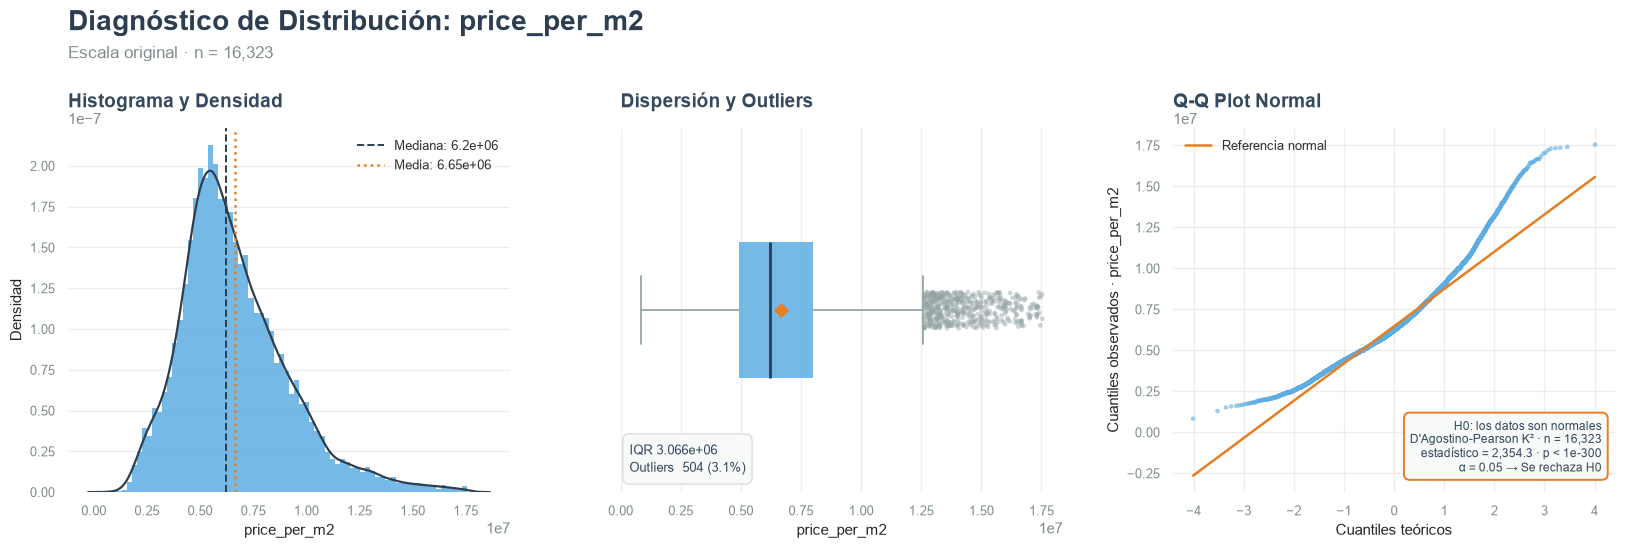

In [51]:
salida_norte = normality_report(df_norte, 'price_per_m2', kde=True, test="auto", neg_strategy="drop")

d:\Externado\Cuarto semestre\bayesiana\proyecto_finca_raiz_colombia\utils\triple_plot.py:673: UserWarning: Shapiro-Wilk assumes a continuous distribution, but the sample has 2,704 distinct values across 3,772 observations. With that many ties the statistic is biased and the p-value is not interpretable.
  name, statistic, p_value, n_test = _normality_test(xs, test)


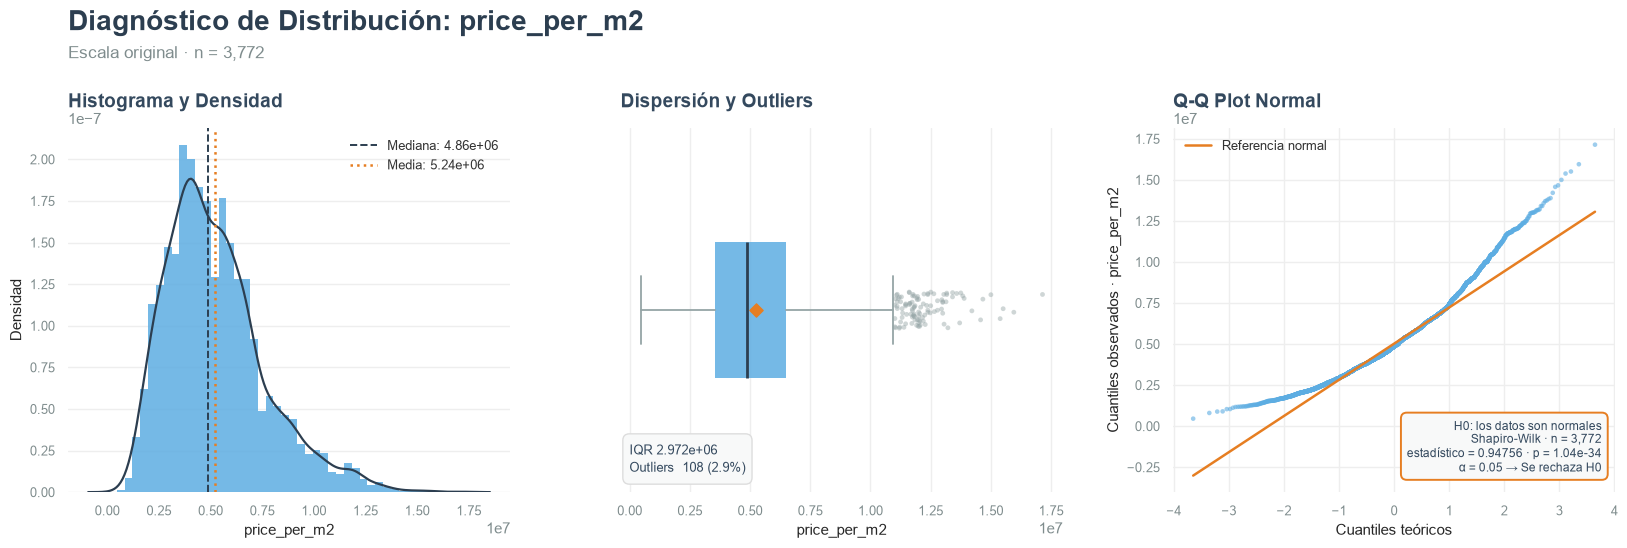

In [52]:
salida_sur = normality_report(df_sur, 'price_per_m2', kde=True, test="auto", neg_strategy="drop")

El resultado de los graficos 3d anteriores es consistente con el comportamiento del precio del metro cuadrado en el norte contra el del sur, pues mientras el precio por metro cuadrado mediano del norte es de 6,200,000 COP en el sur es de 4,860,000 siendo este uno de los factores que hacen que fijar metrajes altos en el sur cambie menos la distribucion de precios que en el norte.